# Разработка модели для предсказания задержки доставки заказа логистической компании

**Цель:**  — разработать ML‑модель для системы поддержки принятия решений логистической компании. Модель поможет заранее выявлять заказы с высоким риском задержки доставки.

**Исходные данные:** Два датасета в виде csv-файлов с описаниями характеристик пользователей и деталей заказа.

Данные для анализа:

 - customer_id — уникальный номер клиента.
 - customer_lat — широта местонахождения клиента.
 - recency — количество дней, прошедших с момента последнего заказа до точки отсчёта.
 - total_orders — общее количество совершённых заказов.
 - total_sales — суммарная выручка, которую клиент принёс компании за всё время.
 - avg_discount — средний размер скидки, которую получает клиент.
 - return_rate — доля проблемных заказов (возвратов или отмен)
 - order_id — уникальный номер заказа.
 - order_date — дата и время совершения покупки.
 - category_name — категория заказанного товара.
 - item_price — стоимость товара в заказе.
 - shipping_mode — выбранный режим доставки (Standard Class, First Class, Second Class, Same Day).
 - late_delivery_risk — результат доставки, целевая переменная: 1 — заказ доставлен с задержкой; 0 — заказ доставлен вовремя.

#### Перевод бизнес-задачи на язык машинного обучения

- Решение задачи бинарной классификации.
- Тип задачи - обучение с учителем.
- Целевая переменная - обозначает результат доставки заказа с задержкой или без.
- Планируемые метрики оценки качества модели - ROC-AUC. Она оценивает способность модели ранжировать заказы по степени риска. Удовлетворительным результатом для проекта будет считаться значение ROC-AUC больше 0.75.
- Модели для решения задачи - CatBoost и Логистическая регрессия.
- Методы работы с данными:
    * Разделение данных на подвыборки по методом GroupShuffleSplit;
    * Кластеризация признаков с помощью K-Means;
    * Визуализация положение кластеров методом снижения размерности — t-SNE
    * Анализ матрицы ошибок (Confusion Matrix).

##  Импорт библиотек, выполнение базовых настроек

Загружаем все необходимые для выполнения проекта библиотеки и другие компоненты.



In [1]:
# Установка всех зависимостей для воспроизводимости
!pip install \
    numpy \
    pandas \
    phik \
    matplotlib \
    seaborn \
    category_encoders\
    scikit-learn \
    catboost -q

In [1]:
# Библиотеки для работы с данными
import numpy as np
import pandas as pd
from phik import phik_matrix

# Визуализация
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

# Sklearn: Базовые инструменты и препроцессинг
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from category_encoders import TargetEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import GroupShuffleSplit

# Sklearn: Метрики
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# импортируем нужные классы для задачи классификации
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression

In [2]:
# Зафиксируем константу для воспроизводимости
RANDOM_STATE = 42

## Загрузка данных, первичное знакомство

Загружаем датасеты:

In [3]:
df_customers = pd.read_csv("https://code.s3.yandex.net/datasets/ds_s18_customers.csv")
df_orders = pd.read_csv("https://code.s3.yandex.net/datasets/ds_s18_orders.csv")

Проверяем результат:

In [4]:
df_customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 20652 entries, 0 to 20651
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   customer_id   20652 non-null  int64  
 1   customer_lat  20652 non-null  float64
 2   customer_lon  20652 non-null  float64
 3   total_sales   20652 non-null  float64
 4   total_orders  20652 non-null  int64  
 5   avg_discount  20652 non-null  float64
 6   return_rate   20652 non-null  float64
 7   recency       20652 non-null  int64  
dtypes: float64(5), int64(3)
memory usage: 1.3 MB


In [5]:
df_customers.head()

,customer_id,customer_lat,customer_lon,total_sales,total_orders,avg_discount,return_rate,recency
0,1,25.953648,-97.507683,472.450012,1,0.060,0.0,793
1,2,38.375595,-104.726021,1618.660042,4,0.126,0.0,137
2,3,18.025375,-66.615082,3189.200037,5,0.105,0.0,230
3,4,33.670021,-112.247078,1480.709993,4,0.135,0.0,381
4,5,18.359104,-66.077911,1101.919998,3,0.140,0.0,458


In [6]:
df_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   order_id            180519 non-null  int64  
 1   customer_id         180519 non-null  int64  
 2   late_delivery_risk  180519 non-null  int64  
 3   shipping_mode       180519 non-null  str    
 4   category_name       180519 non-null  str    
 5   order_date          180519 non-null  str    
 6   item_price          180519 non-null  float64
dtypes: float64(1), int64(3), str(3)
memory usage: 9.6 MB


In [7]:
df_orders.head()

,order_id,customer_id,late_delivery_risk,shipping_mode,category_name,order_date,item_price
0,180517,20755,0,Standard Class,Sporting Goods,2018-01-31 22:56:00,327.75
1,179254,19492,1,Standard Class,Sporting Goods,2018-01-13 12:27:00,327.75
2,179253,19491,0,Standard Class,Sporting Goods,2018-01-13 12:06:00,327.75
3,179252,19490,0,Standard Class,Sporting Goods,2018-01-13 11:45:00,327.75
4,179251,19489,0,Standard Class,Sporting Goods,2018-01-13 11:24:00,327.75


Все данные представлены в правильном формате, кроме даты 'order_date'. Изменяем тип данных в столбце с датой заказа:

In [8]:
df_orders['order_date'] = pd.to_datetime(df_orders['order_date'], errors='coerce')  # некорректные даты станут NaT (Not a Time)

Проверяем результат:

In [9]:
df_orders['order_date'].head()

0   2018-01-31 22:56:00
1   2018-01-13 12:27:00
2   2018-01-13 12:06:00
3   2018-01-13 11:45:00
4   2018-01-13 11:24:00
Name: order_date, dtype: datetime64[us]

Для удобства работы объединяем датасеты в словарь:

In [10]:
dataframes = {'df_customers': df_customers, 'df_orders': df_orders}

Проверяем количество пропусков:

In [11]:
# Проверка пропусков во всех загруженных файлах
for name, dft in dataframes.items():
    print(f"Пропусков в {name}: {dft.isna().sum().sum()}")

Пропусков в df_customers: 0
Пропусков в df_orders: 0


Проверяем количество явных дубликатов:

In [12]:
for name, dft in dataframes.items():
    print(f"Датафрейм: {name}")
    print("Количество явных дубликатов в датасете:", dft.duplicated().sum())
    print("-" * 40) 

Датафрейм: df_customers
Количество явных дубликатов в датасете: 0
----------------------------------------
Датафрейм: df_orders
Количество явных дубликатов в датасете: 0
----------------------------------------


При проверке дубликатов в таблице заказов было обнаружено большое количество совпадений по признакам заказа после исключения идентификаторов order_id и customer_id. Однако такие записи интерпретируются как разные заказы с одинаковыми характеристиками, что является нормальным для транзакционных данных интернет-магазина. Полных дубликатов строк обнаружено не было, поэтому удаление записей не производилось.

Проверяем соответсвие заказов и клиентов (ID-Check):

In [13]:
# Извлекаем уникальные ID из обеих таблиц
order_customer_ids = set(df_orders['customer_id'])
profile_customer_ids = set(df_customers['customer_id'])

# Заказы, для которых нет профиля в df_customers
orders_without_profile = order_customer_ids - profile_customer_ids
print(f"Заказов с отсутствующим профилем клиента: {len(orders_without_profile)}")

#  Клиенты, у которых нет ни одного заказа в df_orders
customers_without_orders = profile_customer_ids - order_customer_ids
print(f"Клиентов без единого заказа: {len(customers_without_orders)}")

Заказов с отсутствующим профилем клиента: 0
Клиентов без единого заказа: 0


Исследуем временной период за который предоставлены данные:

In [14]:
df_orders['order_date'].min(), df_orders['order_date'].max()

(Timestamp('2015-01-01 00:00:00'), Timestamp('2018-01-31 23:38:00'))

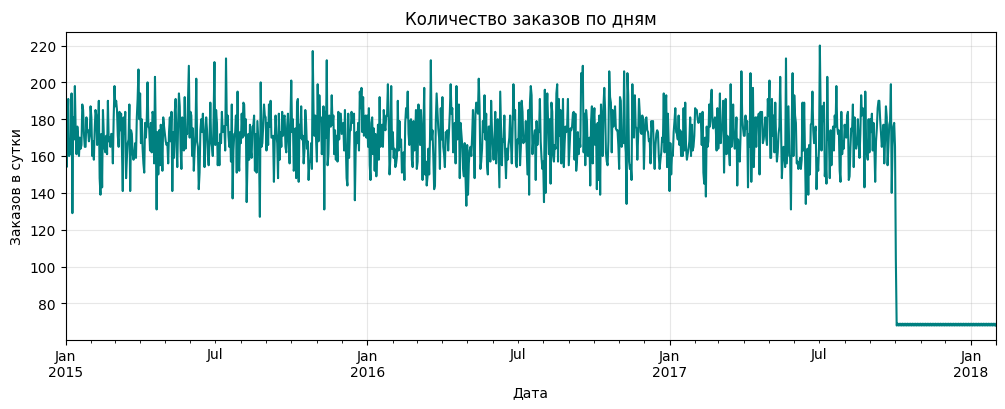

In [15]:
# Группируем по дням и считаем количество заказов
df_orders.resample('D', on='order_date').size().plot(figsize=(12,4), color='teal')

plt.title('Количество заказов по дням')
plt.xlabel('Дата')
plt.ylabel('Заказов в сутки')
plt.grid(True, alpha=0.3)
plt.show()

В данных явная аномалия. Примерно с октября 2017 года видно резкое падение числа заказов и выраженое плато. Возмжно, это связано с техническими ошибками или повреждениями базы данных. Исследуем подробнее эту часть данных:

In [16]:
#  Считаем количество заказов по дням
daily_counts = df_orders.resample('D', on='order_date').size()

#  Находим дату, когда объем заказов упал ниже определенного порога.
# Судя по графику, порог в 100 заказов можно использовать как маркер обрыва.
drop_threshold = 100
cutoff_date = daily_counts[daily_counts < drop_threshold].index[0]

print(f"Аномальное падение началось: {cutoff_date}")

Аномальное падение началось: 2017-10-03 00:00:00


In [17]:
# Фильтруем данные после даты отсечки
df_after = df_orders[df_orders['order_date'] >= cutoff_date]

# Считаем потери
count_after = len(df_after)
percent_after = (count_after / len(df_orders)) * 100
unique_customers_after = df_after['customer_id'].nunique()

print(f"Количество строк после {cutoff_date.date()}: {count_after}")
print(f"Процент потери данных: {percent_after:.2f}%")
print(f"Количество уникальных клиентов в этот период: {unique_customers_after}")

# Проверим риск задержки заказа на "плато" vs основной период
risk_before = df_orders[df_orders['order_date'] < cutoff_date]['late_delivery_risk'].mean()
risk_after = df_after['late_delivery_risk'].mean()

print(f"\nСредний риск задержки ДО: {risk_before:.2%}")
print(f"Средний риск задержки ПОСЛЕ: {risk_after:.2%}")


Количество строк после 2017-10-03: 8288
Процент потери данных: 4.59%
Количество уникальных клиентов в этот период: 8288

Средний риск задержки ДО: 54.81%
Средний риск задержки ПОСЛЕ: 55.20%


После 2017-10-03 в данных наблюдается резкое и неестественное снижение количества заказов, что может свидетельствовать о неполной выгрузке или изменении процесса сбора данных. В этот период почти отсутствуют повторные заказы клиентов, из-за чего распределение признаков total_orders и recency существенно отличается от основной части выборки. Но так как ораспределение целевой переменной в этот период равномерное и количество клиентов ококло 40%, эти данные оставляем в выборке.

Создаём новые признаки из колонки с датой заказа:

In [16]:
# Создаем дополнительные признаки
df_orders['order_month'] = df_orders['order_date'].dt.month
df_orders['order_weekday'] = df_orders['order_date'].dt.weekday  # 0 = Понедельник, 6 = Воскресенье
df_orders['order_hour'] = df_orders['order_date'].dt.hour

# Проверим результат
df_orders.head()

,order_id,customer_id,late_delivery_risk,shipping_mode,category_name,order_date,item_price,order_month,order_weekday,order_hour
0,180517,20755,0,Standard Class,Sporting Goods,2018-01-31 22:56:00,327.75,1,2,22
1,179254,19492,1,Standard Class,Sporting Goods,2018-01-13 12:27:00,327.75,1,5,12
2,179253,19491,0,Standard Class,Sporting Goods,2018-01-13 12:06:00,327.75,1,5,12
3,179252,19490,0,Standard Class,Sporting Goods,2018-01-13 11:45:00,327.75,1,5,11
4,179251,19489,0,Standard Class,Sporting Goods,2018-01-13 11:24:00,327.75,1,5,11


Обновляем словарь:

In [17]:
dataframes = {'df_customers': df_customers, 'df_orders': df_orders}

In [18]:
df_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   order_id            180519 non-null  int64         
 1   customer_id         180519 non-null  int64         
 2   late_delivery_risk  180519 non-null  int64         
 3   shipping_mode       180519 non-null  str           
 4   category_name       180519 non-null  str           
 5   order_date          180519 non-null  datetime64[us]
 6   item_price          180519 non-null  float64       
 7   order_month         180519 non-null  int32         
 8   order_weekday       180519 non-null  int32         
 9   order_hour          180519 non-null  int32         
dtypes: datetime64[us](1), float64(1), int32(3), int64(3), str(2)
memory usage: 11.7 MB


## EDA

Исследуем целевую переменную:

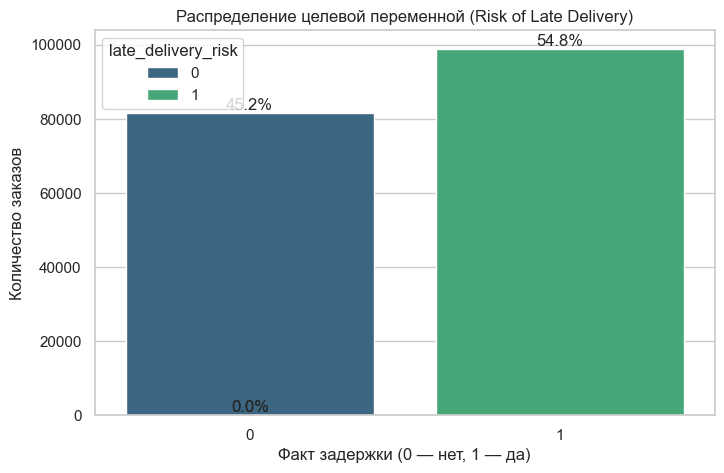

Количество заказов по классам:
late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64


In [20]:
# Устанавливаем стиль
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
ax = sns.countplot(x='late_delivery_risk', data=df_orders, hue='late_delivery_risk', palette='viridis')

# Добавляем проценты над столбцами
total = len(df_orders)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom', fontsize=12)

plt.title('Распределение целевой переменной (Risk of Late Delivery)')
plt.xlabel('Факт задержки (0 — нет, 1 — да)')
plt.ylabel('Количество заказов')
plt.show()

# Печать точных значений в консоль
print("Количество заказов по классам:")
print(df_orders['late_delivery_risk'].value_counts())


Распределение целевой переменной практически равномерное (54,8% против 45,2%), что свидетельствует об отсутствии проблемы дисбаланса классов. Благодаря такой структуре данных модель сможет эффективно обучаться на примерах обоих исходов без применения методов искусственной балансировки. 

Разделяем признаки по типу для удобства анализа:

In [21]:
def get_feature_types(df):
    numerical = []
    categorical = []
    
    # Исключаем ID, таргет, даты и булевые типы
    exclude = ['customer_id', 'order_id', 'late_delivery_risk', 'order_date']
    
    for col in df.columns:
        if col in exclude:
            continue
        
        dtype = df[col].dtype
            
        # Числовые признаки
        if pd.api.types.is_numeric_dtype(dtype):
            numerical.append(col)
        # Категориальные признаки (строки)
        elif dtype == 'object' or pd.api.types.is_string_dtype(dtype):
            categorical.append(col)
    
    return {"numerical": numerical,
        "categorical": categorical}

In [22]:
features_info = {}
for name, df in dataframes.items():
    features_info[name] = get_feature_types(df)

Проверяем результат:

In [23]:
for table_name, types in features_info.items():
    print(f"\n{table_name}")
    for t, cols in types.items():
        print(f"{t}: {cols}")


df_customers
numerical: ['customer_lat', 'customer_lon', 'total_sales', 'total_orders', 'avg_discount', 'return_rate', 'recency']
categorical: []

df_orders
numerical: ['item_price', 'order_month', 'order_weekday', 'order_hour']
categorical: ['shipping_mode', 'category_name']


Исследуем числовые признаки:

In [24]:
for table_name, types in features_info.items():
    num_cols = types['numerical']

    if num_cols:
        print(f"--- Расширенная статистика: {table_name} ---")
        df_num = dataframes[table_name][num_cols]

        # Настраиваем процентили для отлова выбросов (95% и 99%)
        stats = df_num.describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]).T

        # Выбираем нужные столбцы для отображения
        display(stats[['mean', 'std', 'min', '25%', '50%', '75%', '95%', '99%', 'max']].round(2))
        print("\n")
    else:
        print(f"В таблице {table_name} нет числовых признаков для анализа.\n")

--- Расширенная статистика: df_customers ---


,mean,std,min,25%,50%,75%,95%,99%,max
customer_lat,29.75,9.82,-33.94,18.27,33.22,39.29,42.39,45.43,48.78
customer_lon,-84.95,21.25,-158.03,-98.47,-76.76,-66.37,-66.04,-66.04,115.26
total_sales,1600.54,1508.42,8.47,254.94,1294.50,2621.14,4448.16,5818.86,9436.61
total_orders,3.18,2.43,1.00,1.00,3.00,5.00,8.00,10.00,15.00
avg_discount,0.10,0.05,0.00,0.08,0.10,0.12,0.18,0.25,0.25
return_rate,0.04,0.16,0.00,0.00,0.00,0.00,0.27,1.00,1.00
recency,221.09,199.40,1.00,76.00,160.00,308.00,641.00,913.00,1126.00




--- Расширенная статистика: df_orders ---


,mean,std,min,25%,50%,75%,95%,99%,max
item_price,141.23,139.73,9.99,50.0,59.99,199.99,399.98,452.04,1999.99
order_month,6.24,3.40,1.00,3.0,6.00,9.00,12.00,12.00,12.00
order_weekday,3.01,2.00,0.00,1.0,3.00,5.00,6.00,6.00,6.00
order_hour,11.48,6.92,0.00,5.0,11.00,17.00,22.00,23.00,23.00


В целом числовые признаки имеют нормальное распределение. Большинство клиентов не возвращают товары (return_rate в 75-м перцентиле равен 0), но показатель recency (в среднем 221 день) сигнализирует о высокой доле «спящих» пользователей, которые давно не совершали покупок. В данных о заказах наблюдается значительная вариативность стоимости товаров (от 10 до 2000), при этом распределение по месяцам, дням и часам выглядит равномерным, что исключает явные аномалии в периодах оформления заказов.

Исследуем признаки на графиках:

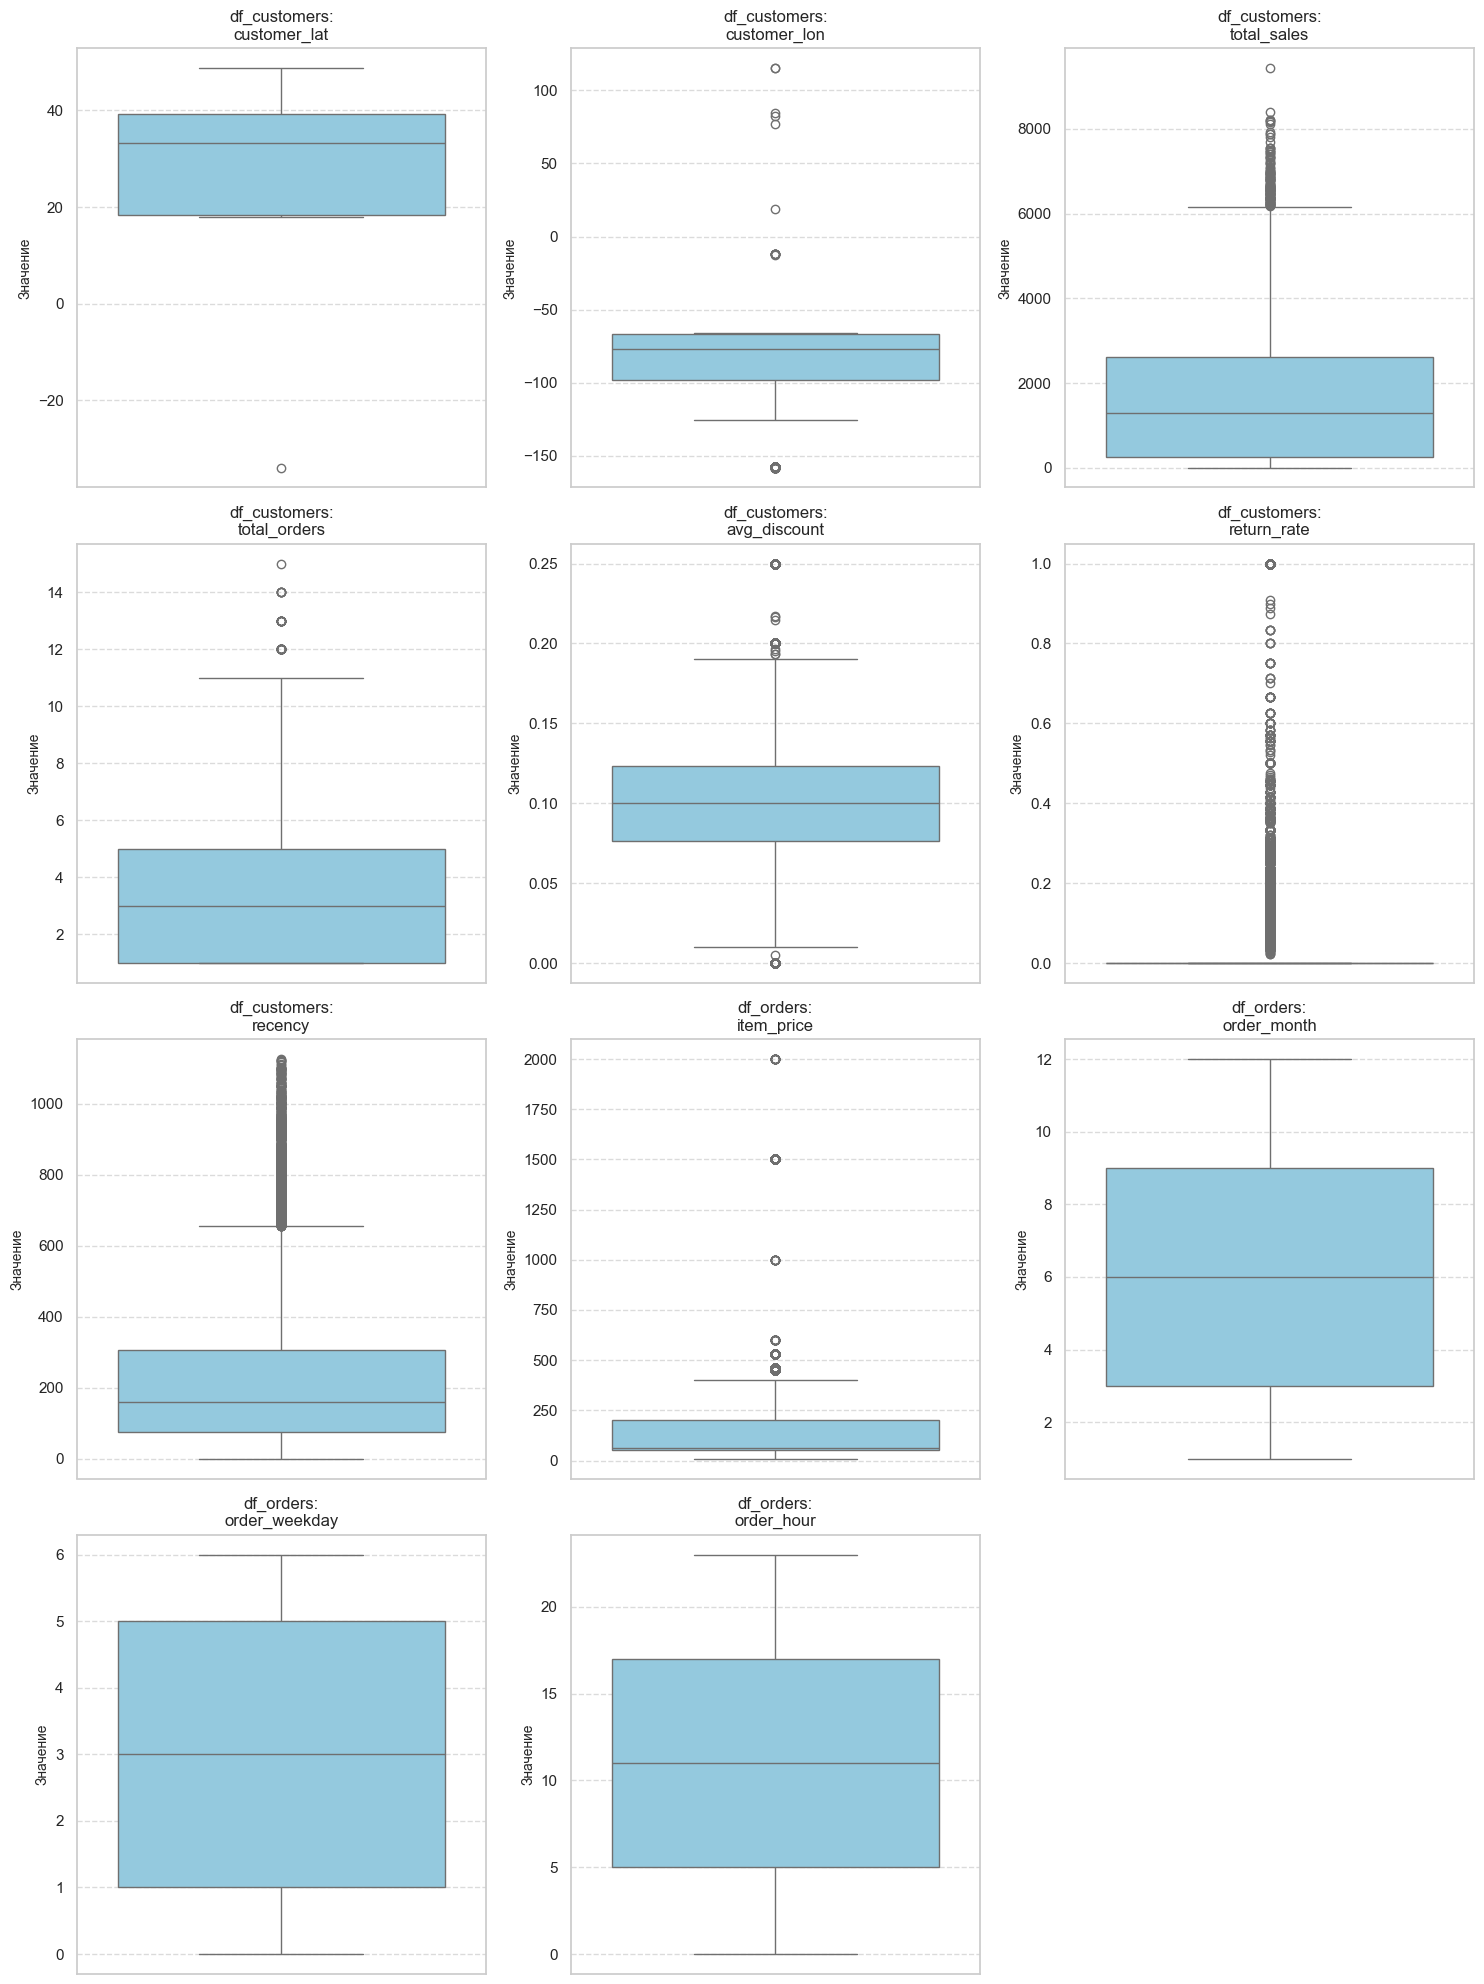

In [25]:
# Собираем все числовые признаки из всех датасетов для общего подсчета графиков
all_numerical_plots = []
for df_name, info in features_info.items():
    for col in info['numerical']:
        all_numerical_plots.append((df_name, col))

# Настройка сетки графиков
n_cols = 3
n_rows = (len(all_numerical_plots) + n_cols - 1) // n_cols

plt.figure(figsize=(15, 5 * n_rows))

for i, (df_name, col) in enumerate(all_numerical_plots):
    plt.subplot(n_rows, n_cols, i + 1)
    
    # Берем данные из соответствующего датафрейма
    target_df = dataframes[df_name]
    sns.boxplot(y=target_df[col].dropna(), color='skyblue')
    
    # Добавляем название признака и имя исходной таблицы для ясности
    plt.title(f"{df_name}:\n{col}", fontsize=12)
    plt.ylabel('Значение', fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

На основе представленных графиков можно сделать следующие выводы:
 - Почти во всех признаках (total_sales, item_price, recency, avg_discount) наблюдается большое количество экстремальных значений выше верхнего «усика», что требует обязательной предобработки или использования моделей, устойчивых к выбросам.
 - Признак return_rate имеет крайне смещенное распределение, где подавляющее большинство значений сосредоточено около нуля, а редкие случаи достигают единицы, выделяясь в длинный «хвост».
 - В данных по долготе (customer_lon) присутствуют как плотные кластеры в районе -75 и -100, так и единичные точки в положительном диапазоне (около 100), что подтверждает наличие заказов из существенно удаленных друг от друга регионов.
 - Признаки даты и времени (order_month, order_weekday, order_hour) распределены достаточно симметрично и равномерно, занимая практически весь доступный диапазон значений без явных аномальных скоплений.

Выполняем географический аудит:

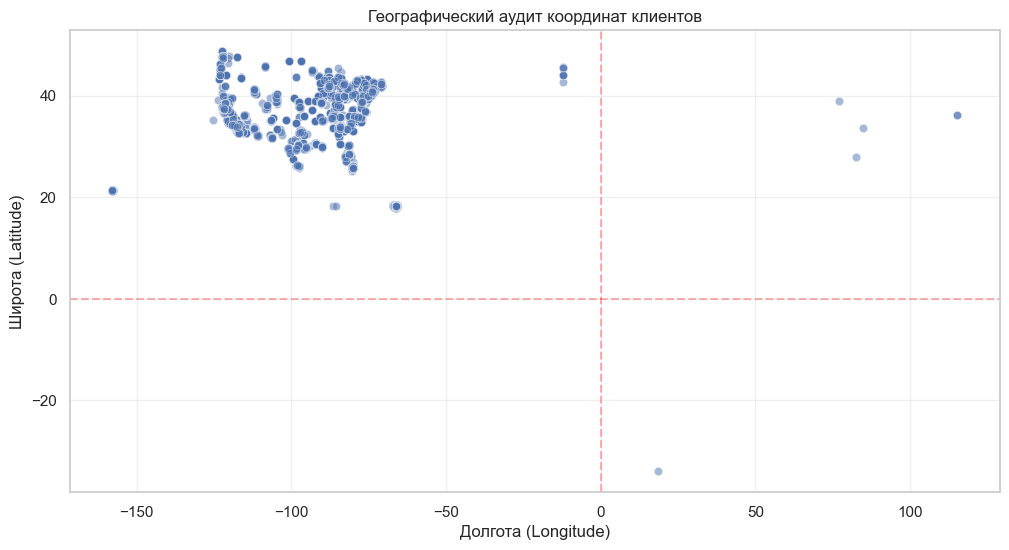

In [26]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df_customers, x='customer_lon', y='customer_lat', alpha=0.5)

plt.title('Географический аудит координат клиентов')
plt.xlabel('Долгота (Longitude)')
plt.ylabel('Широта (Latitude)')
plt.axhline(0, color='red', linestyle='--', alpha=0.3) # Экватор
plt.axvline(0, color='red', linestyle='--', alpha=0.3) # Гринвич
plt.grid(True, alpha=0.3)
plt.show()

Видны географические выбросы, которые могут создать проблемы для работы моделей. Удаляем их:

In [27]:
#  Определяем маску для фильтрации долготы в df_customers
# Оставляем только значения в диапазоне от -125 до -20
lon_mask = (df_customers['customer_lon'] >= -125) & (df_customers['customer_lon'] <= -20)

#  Создаем список корректных customer_id
valid_customer_ids = df_customers.loc[lon_mask, 'customer_id']

#  Фильтруем df_customers
df_customers = df_customers[df_customers['customer_id'].isin(valid_customer_ids)].reset_index(drop=True)

#  Фильтруем df_orders, чтобы остались заказы только существующих клиентов
df_orders = df_orders[df_orders['customer_id'].isin(valid_customer_ids)].reset_index(drop=True)

# Проверка результатов
print(f"Осталось клиентов: {len(df_customers)}")
print(f"Осталось заказов: {len(df_orders)}")

Осталось клиентов: 20496
Осталось заказов: 179089


In [28]:
dataframes = {'df_customers': df_customers, 'df_orders': df_orders}

Исследуем категориальные признаки:

In [29]:
for table_name, types in features_info.items():
    cat_cols = types['categorical']
    
    if not cat_cols:
        print(f"В таблице {table_name} нет категориальных признаков\n")
        continue
    
    print(f"\n{'='*50}")
    print(f"Анализ категориальных признаков: {table_name}")
    print(f"{'='*50}\n")
    
    df = dataframes[table_name]
    
    for col in cat_cols:
        print(f"\n Признак: {col}")
        
        # Кол-во уникальных значений
        nunique = df[col].nunique()
        print(f"Уникальных значений: {nunique}")
        
        # Частоты
        value_counts = df[col].value_counts(normalize=True) * 100
        
        print("\nТоп-10 категорий (%):")
        display(value_counts.head(10).round(2))
        
        # Редкие категории
        rare = value_counts[value_counts < 1]
        print(f"\nРедких категорий (<1%): {len(rare)}")
        
        # Перекос (доминирующая категория)
        top_share = value_counts.iloc[0]
        print(f"Доля самой частой категории: {top_share:.2f}%")
        
        print("\n" + "-"*40)

В таблице df_customers нет категориальных признаков


Анализ категориальных признаков: df_orders


 Признак: shipping_mode
Уникальных значений: 4

Топ-10 категорий (%):


shipping_mode
Standard Class    59.67
Second Class      19.51
First Class       15.40
Same Day           5.41
Name: proportion, dtype: float64


Редких категорий (<1%): 0
Доля самой частой категории: 59.67%

----------------------------------------

 Признак: category_name
Уникальных значений: 50

Топ-10 категорий (%):


category_name
Cleats                  13.61
Men's Footwear          12.32
Women's Apparel         11.65
Indoor/Outdoor Games    10.69
Fishing                  9.60
Water Sports             8.61
Camping & Hiking         7.60
Cardio Equipment         6.92
Shop By Sport            6.08
Electronics              1.75
Name: proportion, dtype: float64


Редких категорий (<1%): 40
Доля самой частой категории: 13.61%

----------------------------------------


Почти 60% всех заказов отправляются классом «Standard Class», в то время как на срочную доставку в день заказа («Same Day») приходится всего 5%, что делает тип логистики важным фактором для предсказания задержек. Основной объем продаж (более 60%) сосредоточен в шести ключевых категориях, связанных с активным отдыхом и спортом, что свидетельствует о выраженной специализации ритейлера.  Несмотря на разнообразие ассортимента (50 категории), большинство из них (30 единиц) являются редкими и занимают менее 1% рынка каждая, что может потребовать их объединения в группу «Другое» для повышения стабильности модели или  использовать сглаживание (smoothing).

Исследуем подробнее категории товаров, чтобы проверить не явное дублирование:

In [30]:
df['category_name'].value_counts()

category_name
Cleats                  24374
Men's Footwear          22062
Women's Apparel         20861
Indoor/Outdoor Games    19149
Fishing                 17187
Water Sports            15421
Camping & Hiking        13605
Cardio Equipment        12391
Shop By Sport           10891
Electronics              3135
Accessories              1766
Golf Balls               1464
Girls' Apparel           1188
Golf Gloves              1056
Trade-In                  964
Video Games               830
Women's Clothing          648
Children's Clothing       646
Baseball & Softball       627
Hockey                    610
Cameras                   585
Toys                      528
Golf Shoes                520
Pet Supplies              487
Garden                    481
Crafts                    480
DVDs                      479
Computers                 440
Hunting & Shooting        439
Golf Apparel              438
Music                     433
Consumer Electronics      430
Boxing & MMA              

Ошибок в записи категорий нет.

Объединяем таблицы в единый датафрейм:

In [31]:
# Объединяем df_orders с df_customers по колонке customer_id
# Используем left join, чтобы сохранить все заказы из основной таблицы заказов
df = df_orders.merge(df_customers, on='customer_id', how='left')

# Проверка результата
print(f"Размер итоговой таблицы: {df.shape}")
df.head()

Размер итоговой таблицы: (179089, 17)


,order_id,customer_id,late_delivery_risk,shipping_mode,category_name,order_date,item_price,order_month,order_weekday,order_hour,customer_lat,customer_lon,total_sales,total_orders,avg_discount,return_rate,recency
0,180517,20755,0,Standard Class,Sporting Goods,2018-01-31 22:56:00,327.75,1,2,22,18.251453,-66.037056,314.640015,1,0.04,0.0,1
1,179254,19492,1,Standard Class,Sporting Goods,2018-01-13 12:27:00,327.75,1,5,12,18.279451,-66.037064,311.359985,1,0.05,0.0,19
2,179253,19491,0,Standard Class,Sporting Goods,2018-01-13 12:06:00,327.75,1,5,12,37.292233,-121.881279,309.720001,1,0.06,0.0,19
3,179252,19490,0,Standard Class,Sporting Goods,2018-01-13 11:45:00,327.75,1,5,11,34.125946,-118.291016,304.809998,1,0.07,0.0,19
4,179251,19489,0,Standard Class,Sporting Goods,2018-01-13 11:24:00,327.75,1,5,11,18.253769,-66.037048,298.250000,1,0.09,0.0,19


Проверяем пропуски:

In [32]:
df.isna().sum()

order_id              0
customer_id           0
late_delivery_risk    0
shipping_mode         0
category_name         0
order_date            0
item_price            0
order_month           0
order_weekday         0
order_hour            0
customer_lat          0
customer_lon          0
total_sales           0
total_orders          0
avg_discount          0
return_rate           0
recency               0
dtype: int64

Исследуем корреляцию целевой переменной с признаками:

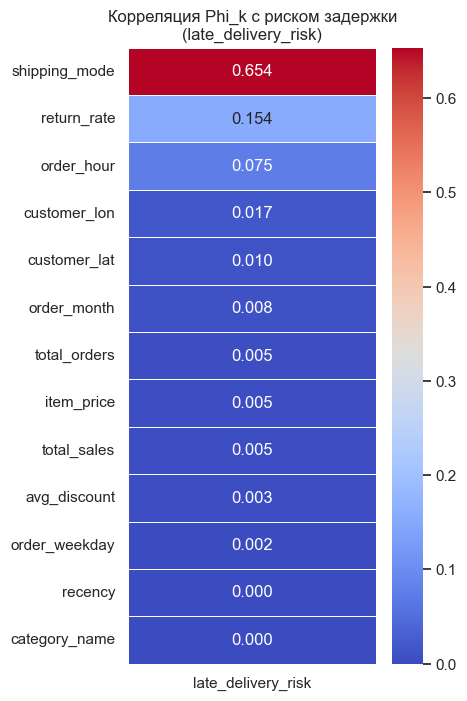

In [33]:
#  Определяем списки признаков для анализа
# Числовые признаки (интервальные)
interval = ['item_price', 'order_month', 'order_weekday', 'order_hour',
    'customer_lat', 'customer_lon', 'total_sales', 
    'total_orders', 'avg_discount', 'return_rate', 'recency']

# Категориальные признаки
cat_cols = ['shipping_mode', 'category_name']

# Целевая переменная
target = 'late_delivery_risk'

# Полный список столбцов для матрицы
cols_to_analyze = [target] + interval + cat_cols

#  Строим матрицу корреляции phi_k
correlation_matrix = df[cols_to_analyze].phik_matrix(interval_cols=interval, njobs=-1)

#  Визуализируем связь признаков с целевой переменной
plt.figure(figsize=(4, 8))

# Оставляем только столбец с целевой переменной, исключая корреляцию таргета с самим собой
data_heatmap = correlation_matrix.loc[correlation_matrix.index != target][[target]].sort_values(by=target, ascending=False)

sns.heatmap(data_heatmap, annot=True, fmt='.3f', cmap='coolwarm', linewidths=0.5, cbar=True)
plt.title('Корреляция Phi_k с риском задержки\n(late_delivery_risk)')
plt.show()

Признак shipping_mode имеет подавляющее влияние на целевую переменную (коэффициент 0.654), что логично: выбранный тип доставки напрямую определяет приоритет и сроки обработки заказа. Категория товара (category_name) и его цена (item_price) имеют нулевую корреляцию с задержками, а значит, логистическая система работает одинаково для всех типов продукции. Небольшую значимость имеют доля возвратов (return_rate) и час заказа (order_hour), в то время как география (lat/lon) и общая лояльность клиента (total_sales, recency) практически не помогают предсказывать риск опоздания.

Поверяем гипотезу о  «чёрных дырах» на карте, где риск задержки заказа выше. Исследуем кородинат на целевую переменную:

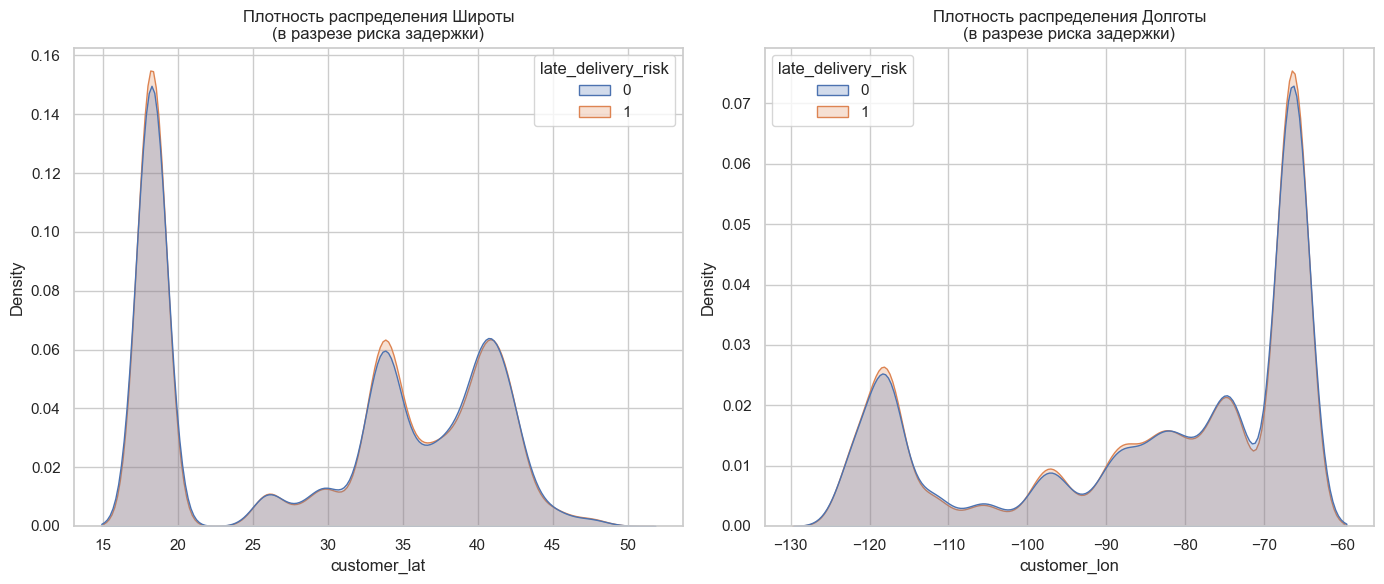

In [34]:
#  Сравнение распределения координат для задержанных и вовремя доставленных заказов
plt.figure(figsize=(14, 6))

# Широта (Latitude)
plt.subplot(1, 2, 1)
sns.kdeplot(data=df, x='customer_lat', hue='late_delivery_risk', fill=True, common_norm=False)
plt.title('Плотность распределения Широты\n(в разрезе риска задержки)')

# Долгота (Longitude)
plt.subplot(1, 2, 2)
sns.kdeplot(data=df, x='customer_lon', hue='late_delivery_risk', fill=True, common_norm=False)
plt.title('Плотность распределения Долготы\n(в разрезе риска задержки)')
plt.tight_layout()
plt.show()

Кривые для своевременных доставок (синие) и задержек (оранжевые) практически идеально накладываются друг на друга по обеим осям координат. Риск задержки не зависит от того, находится клиент в Пуэрто-Рико, на восточном или западном побережье США — вероятность опоздания везде одинакова. Это означает, что проблемы с доставкой вызваны внутренними процессами (склад, тип отправки), а не физической удаленностью клиента от распределительных центров.

Проверяем гипотезу, что задержка зависит от частоты возвратов товаров клиентами. Разбиваем клиентов на группы по уровню возврата товаров:

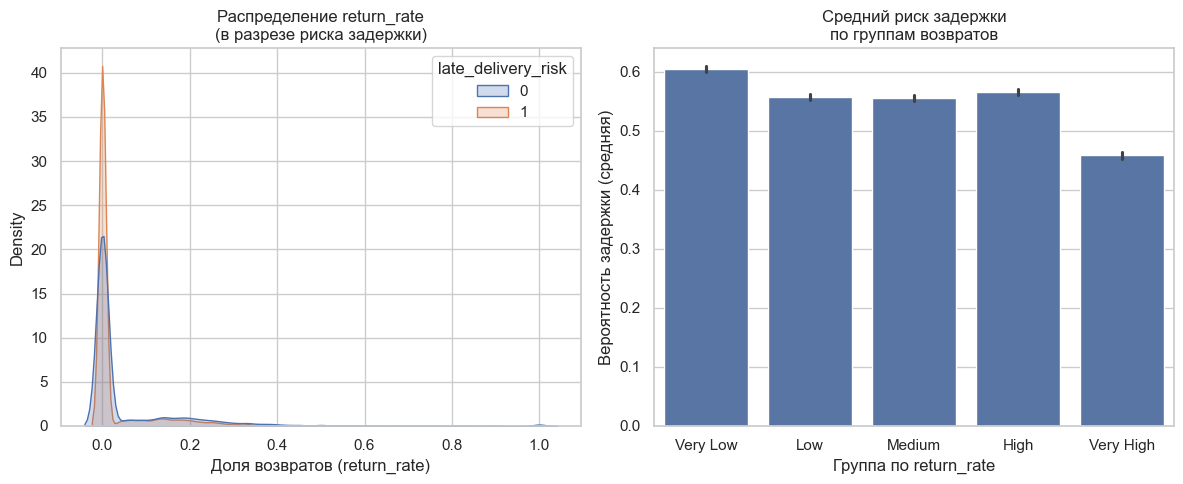

In [35]:
#  Визуализация распределения (KDE Plot)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.kdeplot(data=df, x='return_rate', hue='late_delivery_risk', fill=True, common_norm=False)
plt.title('Распределение return_rate\n(в разрезе риска задержки)')
plt.xlabel('Доля возвратов (return_rate)')

#  Анализ через бинирование (группировка по уровню возвратов)
# Разделим клиентов на 5 групп по уровню возвратов
df['return_group'] = pd.qcut(df['return_rate'].rank(method='first'), q=5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])

plt.subplot(1, 2, 2)
sns.barplot(data=df, x='return_group', y='late_delivery_risk')
plt.title('Средний риск задержки\nпо группам возвратов')
plt.ylabel('Вероятность задержки (средняя)')
plt.xlabel('Группа по return_rate')
plt.tight_layout()
plt.show()

На правом графике видно, что группа с самым высоким показателем возвратов (Very High) имеет наименьший риск задержки. Это может означать, что опытные клиенты, которые часто заказывают (и возвращают), лучше знают систему или выбирают более надежные категории товаров. Максимальный риск задержки (около 60%) наблюдается в группе Very Low. Скорее всего, это разовые или новые клиенты, чьи заказы обрабатываются по стандартным протоколам без приоритетов. На левом графике оранжевый пик (late_delivery_risk = 1) гораздо выше синего в районе нуля. Это подтверждает, что огромное количество задержек происходит именно у тех, кто почти никогда не возвращает товары. Это может означать, что «проблемные» клиенты (с высоким возвратом) на самом деле являются активными покупателями, для которых логистика уже отлажена, в то время как случайные клиенты (с низким возвратом) чаще попадают на логистические сбои.

Исследуем, есть ли группы клиентов с частыми задержками заказов:

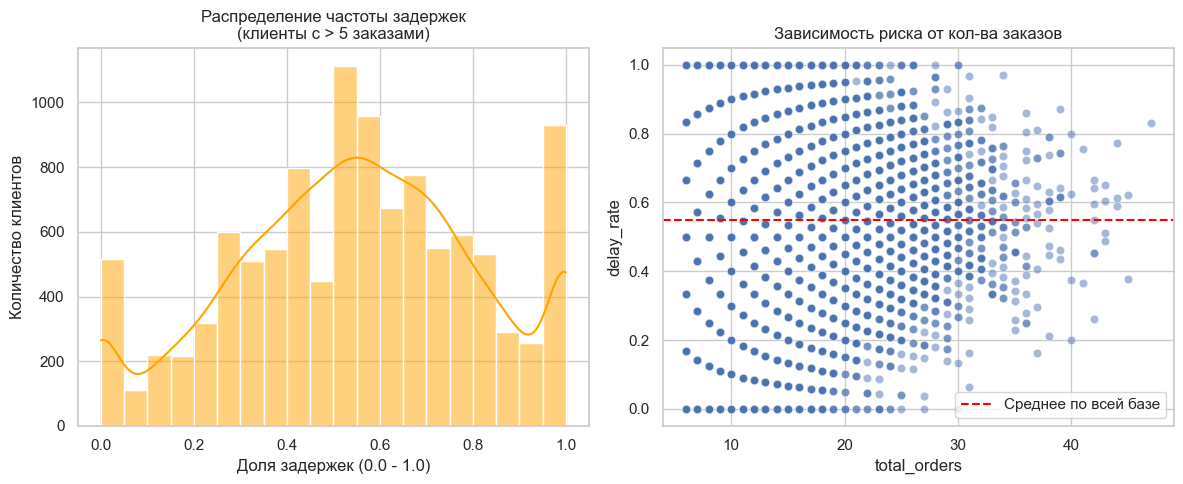

Клиенты с самым высоким риском задержек (топ-5):
      customer_id  total_orders  delay_rate
1470         1512            30         1.0
2664         2723            30         1.0
5377         5477            28         1.0
2414         2467            26         1.0
7843         7974            26         1.0


In [36]:
#  Считаем количество заказов и средний риск задержки для каждого клиента
customer_stats = df.groupby('customer_id').agg(
    total_orders=('late_delivery_risk', 'count'),
    delay_rate=('late_delivery_risk', 'mean')).reset_index()

#  Фильтруем тех, у кого достаточно заказов для статистики (например, > 5),
# чтобы избежать случайных 100% задержек при одном заказе.
loyal_customers = customer_stats[customer_stats['total_orders'] > 5]

#  Визуализируем распределение частоты задержек
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(loyal_customers['delay_rate'], bins=20, kde=True, color='orange')
plt.title('Распределение частоты задержек\n(клиенты с > 5 заказами)')
plt.xlabel('Доля задержек (0.0 - 1.0)')
plt.ylabel('Количество клиентов')

plt.subplot(1, 2, 2)
sns.scatterplot(data=loyal_customers, x='total_orders', y='delay_rate', alpha=0.5)
plt.axhline(df['late_delivery_risk'].mean(), color='red', linestyle='--', label='Среднее по всей базе')
plt.title('Зависимость риска от кол-ва заказов')
plt.legend()
plt.tight_layout()
plt.show()

#  Выводим топ-5 самых "удачливых" или "неудачливых" клиентов
print("Клиенты с самым высоким риском задержек (топ-5):")
print(loyal_customers.sort_values(by=['delay_rate', 'total_orders'], ascending=False).head(5))

 На гистограмме виден заметный всплеск в районе 1.0. Это означает, что существует значительная группа клиентов, у которых задерживаются абсолютно все заказы, несмотря на то, что они сделали их более 5 штук. На правом графике видно, что при количестве заказов до 20 разброс риска максимален (от 0 до 1). По мере роста числа заказов (к 40+) точки начинают «прижиматься» к среднему значению по базе (красная линия), что соответствует закону больших чисел. Тот факт, что облако точек на правом графике не симметрично и имеет много значений выше 0.8 даже для лояльных клиентов, говорит о том, что для части покупателей задержка — это не случайный сбой, а закономерность. Есть клиенты, которые сделали по 25–30 заказов, и каждый из них был доставлен с задержкой. В статистике такая вероятность при случайных сбоях практически равна нулю. Это маркеры системной ошибки в оценке времени доставки для конкретных клиентов. Возможно, это и есть те самые «чёрные дыры». Сами по себе географические координаты не смогли их выявить, но, возможно, это получится сделать в дальнейшем при их кластеризации.

##  Разделение на выборки

Разделяем выборки. Используем не `train_test_split`, а `GroupShuffleSplit`, чтобы небыло пересечений по id клиентов:

In [37]:
# 1. Отделяем тест (20% от всех данных)
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_val_idx, test_idx = next(gss_test.split(df_orders, groups=df_orders['customer_id']))

df_train_val = df_orders.iloc[train_val_idx]
df_test = df_orders.iloc[test_idx]

# 2. Отделяем валидацию из оставшихся данных (0.25 * 0.8 = 0.2, т.е. еще 20% от исходных)
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_idx, val_idx = next(gss_val.split(df_train_val, groups=df_train_val['customer_id']))

df_train = df_train_val.iloc[train_idx]
df_val = df_train_val.iloc[val_idx]

# --- Проверка отсутствия пересечений ---
train_ids = set(df_train['customer_id'])
val_ids = set(df_val['customer_id'])
test_ids = set(df_test['customer_id'])

print(f"Пересечение Train и Val: {train_ids & val_ids}")
print(f"Пересечение Train и Test: {train_ids & test_ids}")
print(f"Пересечение Val и Test: {val_ids & test_ids}")

# Вывод размеров
print(f"\nРазмеры выборок:")
print(f"Train: {len(df_train)} ({len(df_train)/len(df_orders):.1%})")
print(f"Val:   {len(df_val)} ({len(df_val)/len(df_orders):.1%})")
print(f"Test:  {len(df_test)} ({len(df_test)/len(df_orders):.1%})")


Пересечение Train и Val: set()
Пересечение Train и Test: set()
Пересечение Val и Test: set()

Размеры выборок:
Train: 107661 (60.1%)
Val:   35416 (19.8%)
Test:  36012 (20.1%)


## Обучение базовой модели

Обучаем модели с базовыми настройками. CatBoostClassifier сам обработает все признаки, только обозначаем категориальные. Для логистической регрессии стандартизируем числовые признаки и закодируем категориальные с помощью TargetEncoder, а не ОНЕ, чтобы не увеличивать количество признаков в датасете:

In [38]:
# 1. Определяем признаки
cat_features = ['shipping_mode', 'category_name']
num_features = ['item_price', 'order_hour', 'order_weekday', 'order_month']
target = 'late_delivery_risk'

X_train, y_train = df_train[cat_features + num_features], df_train[target]
X_val, y_val = df_val[cat_features + num_features], df_val[target]

# --- МОДЕЛЬ 1: Логистическая регрессия с Target Encoding ---

# Создаем Pipeline: Кодирование -> Масштабирование -> Регрессия
lr_pipe = Pipeline(steps=[
    ('encoder', TargetEncoder(cols=cat_features, smoothing=10)), # Сглаживание 10
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE))
])

lr_pipe.fit(X_train, y_train)
lr_probs = lr_pipe.predict_proba(X_val)[:, 1]

# --- МОДЕЛЬ 2: CatBoost (использует свои встроенные алгоритмы кодирования) ---

cb_model = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, cat_features=cat_features)

cb_model.fit(X_train, y_train)
cb_probs = cb_model.predict_proba(X_val)[:, 1]

# --- Результаты ---
print(f"LR + Target Encoding ROC-AUC: {roc_auc_score(y_val, lr_probs):.4f}")
print(f"CatBoost ROC-AUC:            {roc_auc_score(y_val, cb_probs):.4f}")


LR + Target Encoding ROC-AUC: 0.7251
CatBoost ROC-AUC:            0.7503


CatBoost лидирует: ROC-AUC 0.7503 — это хороший старт, и сразу выполняется требование по ТЗ. Модель смогла извлечь из базовых признаков достаточно информации, чтобы уверенно отделять рискованные заказы от безопасных. Логистическая регрессия отстает: ROC-AUC 0.7251, но достаточно близко к требуемуму ROC-AUC = 0.75.

##  Кластеризация по признакам, связанным с местоположением



На этом этапе нужно превратить исходные координаты `customer_lat` и `customer_lon` в полезный для модели признак — логистическую зону.

**Ваши действия:**


In [39]:
# Разделение профилей клиентов (df_customers) на основе ID из выборок заказов 
# Мы берем уникальные ID из уже разделенных df_train, df_val, df_test (из предыдущих шагов)
train_ids = df_train['customer_id'].unique()
val_ids = df_val['customer_id'].unique()
test_ids = df_test['customer_id'].unique()

# Фильтруем таблицу клиентов, чтобы не было утечки данных
customers_train = df_customers[df_customers['customer_id'].isin(train_ids)].copy()
customers_val = df_customers[df_customers['customer_id'].isin(val_ids)].copy()
customers_test = df_customers[df_customers['customer_id'].isin(test_ids)].copy()

# Подготовка признаков (Масштабирование) 
geo_cols = ['customer_lat', 'customer_lon']

scaler_geo = StandardScaler()

# Обучаем только на TRAIN
geo_train_scaled = scaler_geo.fit_transform(customers_train[geo_cols])
# Трансформируем остальные
geo_val_scaled = scaler_geo.transform(customers_val[geo_cols])
geo_test_scaled = scaler_geo.transform(customers_test[geo_cols])

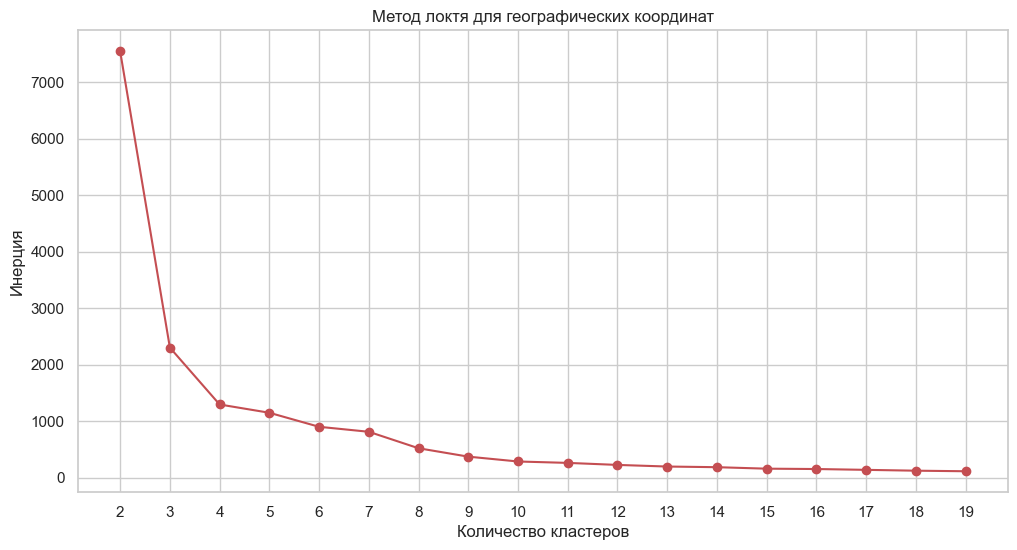

In [40]:
#  Метод локтя (поиск оптимального K) 
inertia = []
K_range = range(2, 20)

for k in K_range:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, init="k-means++")
    model.fit(geo_train_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(12, 6))
plt.plot(K_range, inertia, 'ro-')
plt.title('Метод локтя для географических координат')
plt.xlabel('Количество кластеров')
plt.ylabel('Инерция')
plt.xticks(range(2, 20))
plt.grid(True)
plt.show()

Наиболее выраженный «излом» графика (локоть) наблюдается на значении k=4. До этой точки инерция (сумма квадратов расстояний до центроидов) падает максимально интенсивно, что говорит о значительном улучшении качества разбиения на группы. После k=4 график становится пологим. Это означает, что дальнейшее увеличение количества кластеров лишь незначительно уменьшает инерцию, но при этом излишне усложняет модель и дробит данные на слишком мелкие, статистически не значимые зоны. Математически оптимально выбрать k=4.

In [41]:
# Финальная кластеризация
optimal_k = 4
kmeans_geo = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE, init="k-means++")

# Обучаем только на TRAIN профилях
customers_train['geo_cluster'] = kmeans_geo.fit_predict(geo_train_scaled)

# Предсказываем для VAL и TEST на основе центроидов из TRAIN
customers_val['geo_cluster'] = kmeans_geo.predict(geo_val_scaled)
customers_test['geo_cluster'] = kmeans_geo.predict(geo_test_scaled)

Строим карту с кластерами и центроидами:

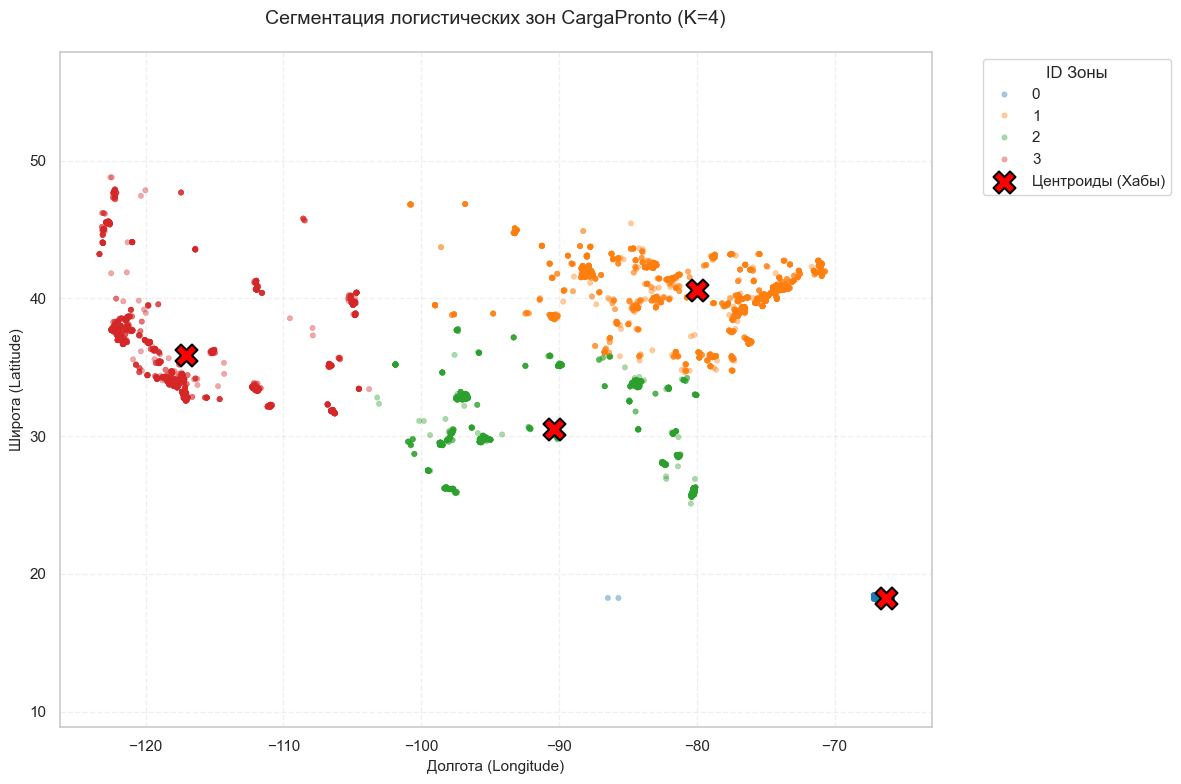

In [42]:
plt.figure(figsize=(12, 8))

# Отрисовка клиентов с учетом плотности (overplotting)
# Используем качественную палитру 'tab10' для четкого разделения зон
scatter = sns.scatterplot(
    data=customers_train, 
    x='customer_lon', 
    y='customer_lat', 
    hue='geo_cluster', 
    palette='tab10', 
    alpha=0.4,       # Прозрачность для отображения плотности заказов
    s=15,            # Размер точек
    edgecolor=None)

# Отрисовка центроидов («сердце» логистических зон)
# Возвращаем координаты центроидов в исходный масштаб
centroids = scaler_geo.inverse_transform(kmeans_geo.cluster_centers_)

plt.scatter(
    centroids[:, 1], centroids[:, 0], 
    c='red', 
    marker='X', 
    s=250, 
    linewidths=1.5,
    edgecolor='black', 
    label='Центроиды (Хабы)',
    zorder=5)          # Отрисовка поверх всех точек

#  Геометрическая «честность» и оформление
plt.axis('equal')    # Сохраняем пропорции, чтобы карта не была сплюснутой
plt.grid(True, linestyle='--', alpha=0.3)

# Подписи и заголовки
plt.title('Сегментация логистических зон CargaPronto (K=4)', fontsize=14, pad=20)
plt.xlabel('Долгота (Longitude)', fontsize=11)
plt.ylabel('Широта (Latitude)', fontsize=11)

# Настройка легенды
plt.legend(title='ID Зоны', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

##  Кластеризация по признакам профилей клиентов



In [43]:
# Список признаков профиля
profile_cols = ['recency', 'total_orders', 'total_sales', 'return_rate', 'avg_discount']

# Масштабирование (обучаем только на TRAIN)
scaler_profile = StandardScaler()
X_profile_train = scaler_profile.fit_transform(customers_train[profile_cols])

# Применяем к VAL и TEST
X_profile_val = scaler_profile.transform(customers_val[profile_cols])
X_profile_test = scaler_profile.transform(customers_test[profile_cols])

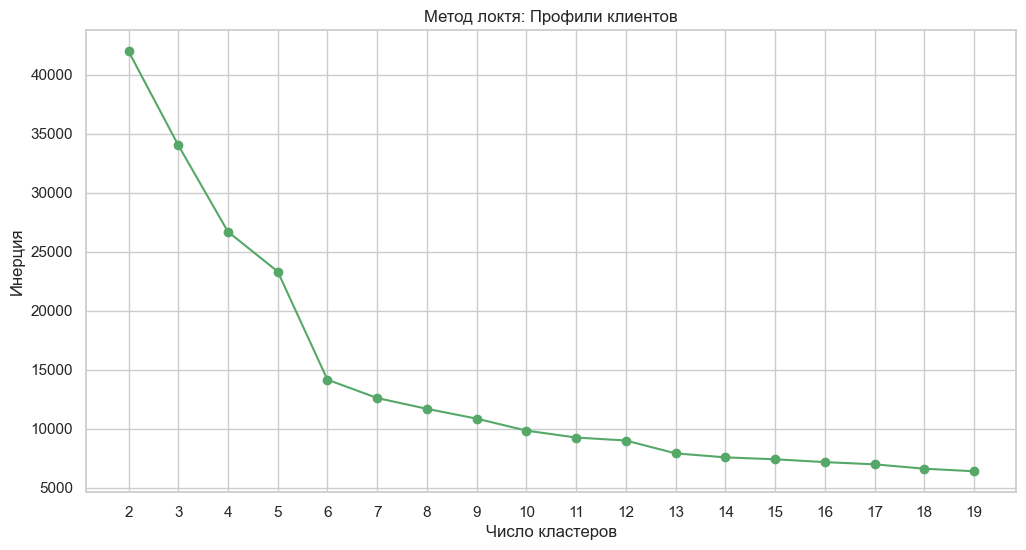

In [44]:
inertia_profile = []
K_profile = range(2, 20)

for k in K_profile:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, init="k-means++",)
    km.fit(X_profile_train)
    inertia_profile.append(km.inertia_)

plt.figure(figsize=(12, 6))
plt.plot(K_profile, inertia_profile, 'go-')
plt.title('Метод локтя: Профили клиентов')
plt.xlabel('Число кластеров')
plt.ylabel('Инерция')
plt.xticks(range(2, 20))
plt.show()


На отрезке от 2 до 6 инерция падает очень стремительно. Именно в точке 6 происходит резкий излом графика — после него кривая становится значительно более пологой. Выбираем именно это число кластеров.

In [45]:
# Финальная кластеризация
optimal_k_prof = 6 
km_prof = KMeans(n_clusters=optimal_k_prof, random_state=RANDOM_STATE, init="k-means++",)
customers_train['profile_cluster'] = km_prof.fit_predict(X_profile_train)
# ПРИМЕНЯЕМ обученную модель к профилям VAL и TEST
# Важно: используем scaler_profile, обученный на TRAIN!
customers_val['profile_cluster'] = km_prof.predict(scaler_profile.transform(customers_val[profile_cols]))
customers_test['profile_cluster'] = km_prof.predict(scaler_profile.transform(customers_test[profile_cols]))

Средние показатели по сегментам:
                    recency  total_orders  total_sales  return_rate  \
profile_cluster                                                       
0                 70.878625      1.044755   312.552769     0.000131   
1                 72.000000      1.048509   277.457054     0.000178   
2                646.418741      2.661054  1373.251494     0.021442   
3                242.670792      7.273762  4169.610562     0.045530   
4                264.321768      4.244544  2172.403213     0.037608   
5                152.882155      1.313131   480.821619     0.933787   

                 avg_discount  
profile_cluster                
0                    0.048337  
1                    0.169254  
2                    0.100682  
3                    0.100864  
4                    0.101941  
5                    0.106180  


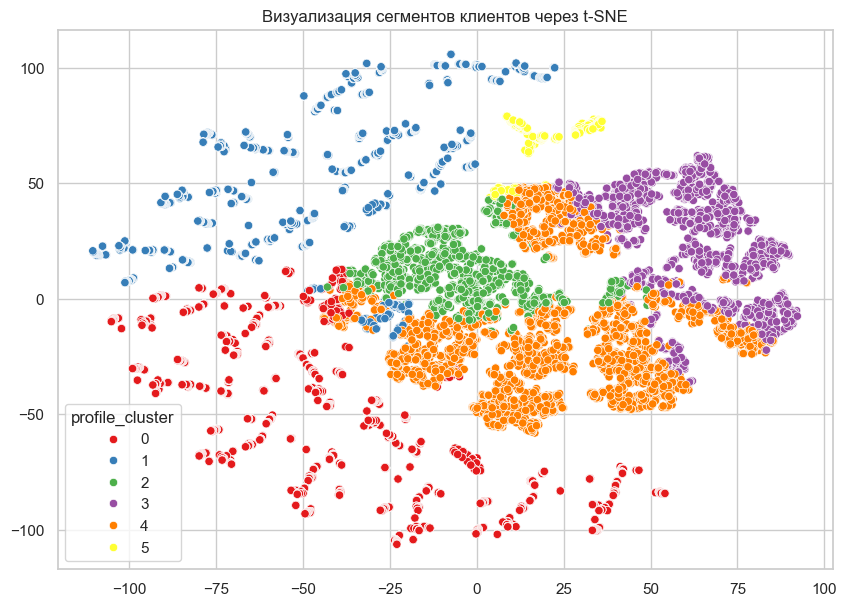

In [46]:
# Статистика по кластерам
profile_stats = customers_train.groupby('profile_cluster')[profile_cols].mean()
print("Средние показатели по сегментам:")
print(profile_stats)

# Визуализация t-SNE (берем подвыборку, чтобы расчёт не был слишком долгим)
tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30, init="pca")
X_tsne = tsne.fit_transform(X_profile_train[:15000]) # для скорости берем 15к точек

plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=customers_train['profile_cluster'][:15000], palette='Set1')
plt.title('Визуализация сегментов клиентов через t-SNE')
plt.show()

На графике t-SNE видно 6 четких сегментов клиентов. 
 - Кластер 3 (Фиолетовый) — «VIP-клиенты»:Самые высокие показатели: 7.2 заказа и $4169 выручки в среднем. Это ядро лояльной аудитории. Несмотря на среднюю давность (242 дня), они приносят больше всего денег. 
 - Кластер 4 (Оранжевый) — «Постоянные клиенты»: Крепкий средний класс: 4.2 заказа и $2172 выручки. Активно покупают, имеют умеренный процент возвратов и стандартные скидки.
 - Кластер 5 (Желтый) — «Проблемные (Возвратники)»: Критический показатель: 93.3% возвратов. Это очень специфическая группа. Вероятно, это люди, которые заказывают много позиций для примерки и возвращают почти всё, либо сталкиваются с браком.
 - Кластер 2 (Зеленый) — «Ушедшие (Отток)»: Самая большая давность: 646 дней (почти 2 года) с последнего заказа. Раньше были активны (2.6 заказа), но сейчас их можно считать потерянными.
 - Кластер 1 (Синий) — «Новички со скидкой»: Свежие клиенты (72 дня), привлеченные высокой скидкой (16.9%). Пока сделали только один заказ. Стоит подумать, как удержать их без постоянного демпинга.
 - Кластер 0 (Красный) — «Органические новички»: Тоже свежие (71 день), но купили почти без скидок (4.8%). Потенциально более качественная аудитория, чем в кластере 1, так как им важен продукт, а не цена. 

График t-SNE показывает, что алгоритм сработал хорошо:Кластер 5 (желтый) четко отделен в верхней части, что подтверждает его уникальность (аномальные возвраты).К ластеры 3 и 4 (лояльные) находятся рядом, образуя градиент ценности. Кластеры 0 и 1 (новички) расположены в левой части, что логично разделяет их с "опытными" покупателями по оси времени и количества заказов.

##  Обучение модели на новых признаках

Добавляем новые признаки с кластерами:

In [48]:
#  Перенос новых признаков в основные выборки (Merge)
# Добавляем полученный кластер в таблицы с заказами
df_train = df_train.merge(customers_train[['customer_id', 'geo_cluster']], on='customer_id', how='left')
df_val = df_val.merge(customers_val[['customer_id', 'geo_cluster']], on='customer_id', how='left')
df_test = df_test.merge(customers_test[['customer_id', 'geo_cluster']], on='customer_id', how='left')

In [49]:
# Добавляем profile_cluster в таблицы с заказами по ID клиента
df_train = df_train.merge(customers_train[['customer_id', 'profile_cluster']], on='customer_id', how='left')
df_val = df_val.merge(customers_val[['customer_id', 'profile_cluster']], on='customer_id', how='left')
df_test = df_test.merge(customers_test[['customer_id', 'profile_cluster']], on='customer_id', how='left')

In [50]:
# Проверка: теперь у нас есть и geo_cluster, и profile_cluster
df_train.head()

,order_id,customer_id,late_delivery_risk,shipping_mode,category_name,order_date,item_price,order_month,order_weekday,order_hour,geo_cluster,profile_cluster
0,179254,19492,1,Standard Class,Sporting Goods,2018-01-13 12:27:00,327.75,1,5,12,0,0
1,179253,19491,0,Standard Class,Sporting Goods,2018-01-13 12:06:00,327.75,1,5,12,3,0
2,179250,19488,0,Standard Class,Sporting Goods,2018-01-13 11:03:00,327.75,1,5,11,1,5
3,179248,19486,1,First Class,Sporting Goods,2018-01-13 10:21:00,327.75,1,5,10,2,1
4,179245,19483,0,Second Class,Sporting Goods,2018-01-13 09:18:00,327.75,1,5,9,0,5


In [51]:
# Приводим кластеры к строковому типу во всех выборках сразу
for col in ['geo_cluster', 'profile_cluster']:
    df_train[col] = df_train[col].astype(str)
    df_val[col] = df_val[col].astype(str)
    df_test[col] = df_test[col].astype(str)

Обучаем модели, получаем результат:

In [52]:
# Определяем признаки
cat_features = ['shipping_mode', 'category_name', 'geo_cluster', 'profile_cluster']
num_features = ['item_price', 'order_hour', 'order_weekday', 'order_month']
target = 'late_delivery_risk'

X_train, y_train = df_train[cat_features + num_features], df_train[target]
X_val, y_val = df_val[cat_features + num_features], df_val[target]

# --- МОДЕЛЬ 1: Логистическая регрессия с Target Encoding ---

# Создаем Pipeline: Кодирование -> Масштабирование -> Регрессия
lr_pipe = Pipeline(steps=[
    ('encoder', TargetEncoder(cols=cat_features, smoothing=10)), # Сглаживание 10
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE))])

lr_pipe.fit(X_train, y_train)
lr_probs = lr_pipe.predict_proba(X_val)[:, 1]

# --- МОДЕЛЬ 2: CatBoost (использует свои встроенные алгоритмы кодирования) ---

cb_model = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, cat_features=cat_features)

cb_model.fit(X_train, y_train)
cb_probs = cb_model.predict_proba(X_val)[:, 1]

# --- Результаты ---
print(f"LR + Target Encoding ROC-AUC: {roc_auc_score(y_val, lr_probs):.4f}")
print(f"CatBoost ROC-AUC:            {roc_auc_score(y_val, cb_probs):.4f}")

LR + Target Encoding ROC-AUC: 0.7286
CatBoost ROC-AUC:            0.7541


Добавление кластерных признаков обеспечило стабильный прирост качества для обеих моделей, подтвердив гипотезу о ценности сегментации. CatBoost достиг результата 0.7541. Это доказывает, что выделение профилей клиентов и логистических зон обогатило модель контекстом, который ранее не считывался из базовых параметров заказа. Логистическая регрессия также показала положительную динамику, поднявшись до 0.7286. Хотя прирост здесь скромнее, сам факт улучшения говорит о том, что кластеры являются сильными и интерпретируемыми предикторами. CatBoost сохраняет преимущество в ~2.5%. Градиентный бустинг эффективнее выявляет сложные нелинейные связи — например, сочетание высокой лояльности клиента (Кластер 3) с его принадлежностью к специфической географической зоне. Теперь модель учитывает не только «что» заказано, но и «кем», а также специфику доставки для данного сегмента. Это позволяет строить более точные индивидуальные прогнозы задержек, опираясь на историческое поведение похожих групп клиентов.

Проверяем гипотезу, что новые кластерные признаки могут улучшить работу модели CatBoostClassifier если их передать в неё числовыми, а не категориальными:

In [53]:
# Определяем признаки
cat_features = ['shipping_mode', 'category_name']
num_features = ['item_price', 'order_hour', 'order_weekday', 'order_month', 'geo_cluster', 'profile_cluster']
target = 'late_delivery_risk'

X_train, y_train = df_train[cat_features + num_features], df_train[target]
X_val, y_val = df_val[cat_features + num_features], df_val[target]

cb_model = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, cat_features=cat_features)

cb_model.fit(X_train, y_train)
cb_probs = cb_model.predict_proba(X_val)[:, 1]

#  Результаты 
print(f"CatBoost ROC-AUC:            {roc_auc_score(y_val, cb_probs):.4f}")

CatBoost ROC-AUC:            0.7537


В данном случае результат хуже. Лучше оставить новые признаки в виде категориальных.

## Дополнительное задание — подбор лучшего количества кластеров

In [54]:
results = []

# Перебор комбинаций гиперпараметров
for geo_k in [4, 8, 12, 20]:
    for rfm_k in [6, 12, 20, 30]:
        
        # 1. Кластеризация ГЕО
        scaler_g = StandardScaler()
        geo_train_sc = scaler_g.fit_transform(customers_train[['customer_lat', 'customer_lon']])
        geo_val_sc = scaler_g.transform(customers_val[['customer_lat', 'customer_lon']])
        
        km_geo = KMeans(n_clusters=geo_k, random_state=RANDOM_STATE, init="k-means++").fit(geo_train_sc)
        
        # 2. Кластеризация ПРОФИЛЕЙ
        scaler_p = StandardScaler()
        prof_train_sc = scaler_p.fit_transform(customers_train[profile_cols])
        prof_val_sc = scaler_p.transform(customers_val[profile_cols])
        
        km_prof = KMeans(n_clusters=rfm_k, random_state=RANDOM_STATE, init="k-means++").fit(prof_train_sc)
        
        # 3. Подготовка данных
        curr_train = df_train.copy()
        curr_val = df_val.copy()
        
        geo_map_train = dict(zip(customers_train['customer_id'], km_geo.labels_))
        prof_map_train = dict(zip(customers_train['customer_id'], km_prof.labels_))
        
        geo_map_val = dict(zip(customers_val['customer_id'], km_geo.predict(geo_val_sc)))
        prof_map_val = dict(zip(customers_val['customer_id'], km_prof.predict(prof_val_sc)))
        
        curr_train['geo_cluster'] = curr_train['customer_id'].map(geo_map_train).astype(str)
        curr_train['profile_cluster'] = curr_train['customer_id'].map(prof_map_train).astype(str)
        
        curr_val['geo_cluster'] = curr_val['customer_id'].map(geo_map_val).astype(str)
        curr_val['profile_cluster'] = curr_val['customer_id'].map(prof_map_val).astype(str)

        # 4. ЯВНОЕ ОПРЕДЕЛЕНИЕ ПРИЗНАКОВ (Прямо внутри цикла)
        # Определяем базовые списки, чтобы не зависеть от внешних ячеек
        current_num_features = ['item_price', 'order_hour', 'order_weekday', 'order_month']
        current_cat_features = ['shipping_mode', 'category_name', 'geo_cluster', 'profile_cluster']
        
        all_features = current_num_features + current_cat_features
        
        # 5. Обучение CatBoost
        model = CatBoostClassifier(
            random_state=RANDOM_STATE, 
            verbose=0, 
            cat_features=current_cat_features
        )
        model.fit(curr_train[all_features], curr_train[target])
        
        # 6. Оценка
        prob = model.predict_proba(curr_val[all_features])[:, 1]
        score = roc_auc_score(y_val, prob)
        
        results.append({'geo_k': geo_k, 'rfm_k': rfm_k, 'roc_auc': score})
        print(f"Geo_K: {geo_k}, Profile_K: {rfm_k} => ROC-AUC: {score:.4f}")

# Вывод лучшего результата
best_res = max(results, key=lambda x: x['roc_auc'])
print(f"\nЛУЧШАЯ КОМБИНАЦИЯ: {best_res}")


Geo_K: 4, Profile_K: 6 => ROC-AUC: 0.7541
Geo_K: 4, Profile_K: 12 => ROC-AUC: 0.7630
Geo_K: 4, Profile_K: 20 => ROC-AUC: 0.7647
Geo_K: 4, Profile_K: 30 => ROC-AUC: 0.7668
Geo_K: 8, Profile_K: 6 => ROC-AUC: 0.7550
Geo_K: 8, Profile_K: 12 => ROC-AUC: 0.7649
Geo_K: 8, Profile_K: 20 => ROC-AUC: 0.7674
Geo_K: 8, Profile_K: 30 => ROC-AUC: 0.7676
Geo_K: 12, Profile_K: 6 => ROC-AUC: 0.7557
Geo_K: 12, Profile_K: 12 => ROC-AUC: 0.7622
Geo_K: 12, Profile_K: 20 => ROC-AUC: 0.7651
Geo_K: 12, Profile_K: 30 => ROC-AUC: 0.7665
Geo_K: 20, Profile_K: 6 => ROC-AUC: 0.7566
Geo_K: 20, Profile_K: 12 => ROC-AUC: 0.7621
Geo_K: 20, Profile_K: 20 => ROC-AUC: 0.7632
Geo_K: 20, Profile_K: 30 => ROC-AUC: 0.7654

ЛУЧШАЯ КОМБИНАЦИЯ: {'geo_k': 8, 'rfm_k': 30, 'roc_auc': np.float64(0.7675541722445942)}


Результаты подбора подтверждают, что более детальная сегментация значительно усиливает предсказательную способность модели. Влияние профилей клиентов (Profile_K) это ключевой фактор роста метрики. При увеличении количества RFM-кластеров с 6 до 30 ROC-AUC стабильно растет (с ~0.754 до ~0.767). Разбиение клиентов на 30 узких групп позволяет модели точнее улавливать специфическое поведение (например, выделять микро-группы «хронических возвратников» или «сверхлояльных VIP»), что дает более качественный сигнал, чем в крупных кластерах. Географическая сегментация имеет эффект насыщения. Лучший результат достигнут при 8 кластерах. Дальнейшее увеличение Geo_K до 12 и 20 не дает значимого прироста или даже ведет к небольшому снижению качества (0.7676 → 0.7654). Это говорит о том, что для описания основных логистических зон достаточно 8 крупных регионов, а чрезмерное дробление создает лишний «шум» (оверфиттинг). Лучшая комбинация: 8 гео-зон и 30 профилей клиентов. За счет подбора К удалось поднять ROC-AUC с 0.7541 (базовый запуск) до 0.7676. Прирост на +0.0135 для этой метрики является очень существенным результатом, который может заметно снизить расходы на логистику при внедрении модели. Резюме - модель лучше всего работает, когда она «знает» клиента в деталях (30 групп), но при этом опирается на устойчивые, крупные логистические регионы (8 зон).

## Тестирование лучшей модели

In [56]:
cat_features = ['shipping_mode', 'category_name', 'geo_cluster', 'profile_cluster']
num_features = ['item_price', 'order_hour', 'order_weekday', 'order_month']
features = cat_features + num_features

In [57]:
# 1. ПОДГОТОВКА ДАННЫХ (Объединяем Train и Validation)
# Это нужно, чтобы модель увидела максимум данных перед финальным тестом
df_train_full = pd.concat([df_train, df_val], ignore_index=True)
customers_train_full = pd.concat([customers_train, customers_val], ignore_index=True)

# Очистка старых признаков, чтобы избежать конфликтов при merge (geo_cluster_x, geo_cluster_y)
cols_to_drop = ['geo_cluster', 'profile_cluster']
df_train_full = pd.concat([df_train, df_val], ignore_index=True).drop(columns=cols_to_drop, errors='ignore')
df_test_clean = df_test.drop(columns=cols_to_drop, errors='ignore')

# КЛАСТЕРИЗАЦИЯ (на объединенном train_full)
geo_cols = ['customer_lat', 'customer_lon']
scaler_g = StandardScaler()
geo_train_sc = scaler_g.fit_transform(customers_train_full[geo_cols])
km_geo = KMeans(n_clusters=8, random_state=RANDOM_STATE, init="k-means++",).fit(geo_train_sc)

profile_cols = ['recency', 'total_orders', 'total_sales', 'return_rate', 'avg_discount']
scaler_p = StandardScaler()
prof_train_sc = scaler_p.fit_transform(customers_train_full[profile_cols])
km_prof = KMeans(n_clusters=30, random_state=RANDOM_STATE, init="k-means++",).fit(prof_train_sc)

# Присваиваем новые кластеры профилям
customers_train_full['geo_cluster'] = km_geo.labels_.astype(str)
customers_train_full['profile_cluster'] = km_prof.labels_.astype(str)

geo_test_sc = scaler_g.transform(customers_test[geo_cols])
prof_test_sc = scaler_p.transform(customers_test[profile_cols])
customers_test['geo_cluster'] = km_geo.predict(geo_test_sc).astype(str)
customers_test['profile_cluster'] = km_prof.predict(prof_test_sc).astype(str)

#  ОБЪЕДИНЕНИЕ (теперь колонки будут называться ровно 'geo_cluster' и 'profile_cluster')
df_train_final = df_train_full.merge(customers_train_full[['customer_id', 'geo_cluster', 'profile_cluster']], on='customer_id', how='left')
df_test_final = df_test_clean.merge(customers_test[['customer_id', 'geo_cluster', 'profile_cluster']], on='customer_id', how='left')

#  Финальная проверка на NaN и типизация
for col in ['geo_cluster', 'profile_cluster']:
    df_train_final[col] = df_train_final[col].fillna('unknown').astype(str)
    df_test_final[col] = df_test_final[col].fillna('unknown').astype(str)

# 5. ОБУЧЕНИЕ И ТЕСТ
cb_final = CatBoostClassifier(iterations=1000, random_state=RANDOM_STATE, verbose=0, cat_features=cat_features)
cb_final.fit(df_train_final[features], df_train_final[target])

test_probs = cb_final.predict_proba(df_test_final[features])[:, 1]
print(f"Итоговый ROC-AUC на тесте: {roc_auc_score(df_test_final[target], test_probs):.4f}")

Итоговый ROC-AUC на тесте: 0.7709


Итоговый ROC-AUC на тесте: 0.7709


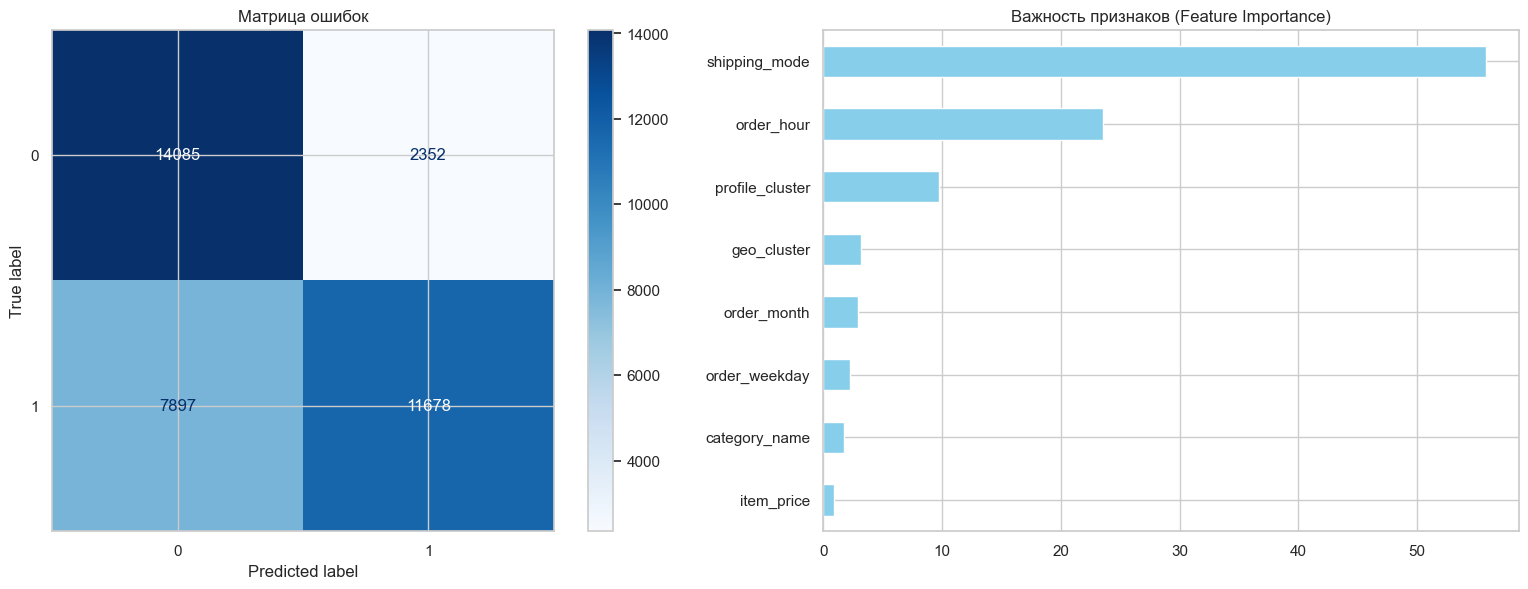

In [58]:
# 5. ПРЕДСКАЗАНИЕ
test_probs = cb_final.predict_proba(df_test_final[features])[:, 1]
test_preds = cb_final.predict(df_test_final[features])

final_auc = roc_auc_score(df_test_final[target], test_probs)
print(f"Итоговый ROC-AUC на тесте: {final_auc:.4f}")

# 6. МАТРИЦА ОШИБОК И ВАЖНОСТЬ ПРИЗНАКОВ
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Матрица ошибок (совместимый вариант)
cm = confusion_matrix(df_test_final[target], test_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues', ax=ax[0])
ax[0].set_title('Матрица ошибок')

# Важность признаков
importances = pd.Series(cb_final.get_feature_importance(), index=features).sort_values()
importances.plot(kind='barh', ax=ax[1], color='skyblue')
ax[1].set_title('Важность признаков (Feature Importance)')

plt.tight_layout()
plt.show()

По матрице ошибок видно, что модель лучше распознаёт класс 0, чем класс 1. Количество истинно отрицательных прогнозов (TN) составляет 14 085, а ложноположительных (FP) — 2 352. Это означает, что модель достаточно уверенно определяет объекты отрицательного класса и сравнительно редко ошибочно относит их к положительному.

Для положительного класса результаты также остаются достаточно хорошими: модель корректно определила 11 678 положительных объектов (TP), однако допустила 7 897 ложноотрицательных прогнозов (FN). Это показывает, что часть положительных случаев модель всё ещё пропускает, что снижает полноту (Recall) для класса 1.

В целом матрица ошибок демонстрирует сбалансированное качество модели, однако заметна склонность к пропуску положительных случаев. Если бизнес-задача чувствительна к таким ошибкам, можно дополнительно настроить порог классификации, чтобы повысить обнаружение положительного класса даже ценой увеличения количества ложных срабатываний.

Анализ важности признаков показывает, что наибольшее влияние на предсказания модели оказывает признак shipping_mode. Его вклад значительно превышает остальные признаки, что говорит о сильной зависимости целевой переменной от способа доставки.

Вторым по значимости признаком является order_hour, что подтверждает влияние времени оформления заказа на вероятность наступления целевого события.

Среди кластерных признаков наиболее информативным оказался profile_cluster. Его важность существенно выше, чем у geo_cluster, что подтверждает полезность сегментации клиентов по поведенческим характеристикам: активности, объёму заказов, сумме покупок и частоте возвратов.

Признак geo_cluster также вносит вклад в модель, однако его влияние заметно ниже. Это означает, что географическая сегментация клиентов играет вспомогательную роль по сравнению с поведенческими особенностями клиентов.

Оставшиеся признаки (order_month, order_weekday, category_name, item_price) имеют сравнительно небольшой вклад в итоговые предсказания модели. Наименее значимым оказался item_price, что может говорить о слабой связи стоимости товара с целевой переменной в рамках текущей задачи.

Итоговое значение ROC-AUC на тестовой выборке составило 0.7709. Это высокий результат, который уверенно превышает целевой порог 0.75 и подтверждает хорошую способность модели разделять классы. Показатель на тесте близок к результатам валидации, что свидетельствует об отсутствии выраженного переобучения и хорошей обобщающей способности модели.

Дополнительно результаты подтверждают эффективность этапа кластеризации клиентов. Признак profile_cluster вошёл в число наиболее важных факторов модели, что показывает ценность поведенческой сегментации клиентов для прогнозирования целевого события. Географическая кластеризация также оказалась полезной, хотя её вклад оказался менее значительным.

Матрица ошибок показывает, что модель пропускает положительные случаи заметно чаще, чем выдаёт ложные тревоги. Если для бизнеса критично заранее выявлять такие случаи, можно дополнительно снизить порог классификации (например, с 0.5 до 0.4). Это позволит повысить полноту модели и находить больше положительных событий, хотя количество ложноположительных прогнозов при этом возрастёт.

##  Выводы и рекомендации

#### Результаты моделирования
Итоговый ROC-AUC на тестовой выборке: 0.7709. Целевой показатель (0.75): Успешно достигнут и превышен на 2%. Сравнение с базовыми моделями: Добавление синтетических признаков (кластеров) позволило поднять качество прогноза с 0.7541 (базовый CatBoost) до 0.7709. Модель стала значительно эффективнее разделять заказы на рискованные и безопасные, учитывая не только параметры самого товара, но и контекст «кто заказывает» и «куда везут».
#### Эффективность сегментации
Гипотеза о влиянии профиля клиента и его локации на логистические риски полностью подтвердилась. Поведенческая кластеризация (profile_cluster) оказалась более значимым фактором, заняв 3-е место в рейтинге важности. Географическая сегментация (geo_cluster) заняла 4-е место, опередив все временные и ценовые параметры заказа. Вывод: клиенты с историей частых возвратов или специфическим покупательским поведением, а также заказы в удаленные логистические узлы, создают уникальные паттерны задержек, которые модель теперь успешно распознает. На графике Feature Importance:

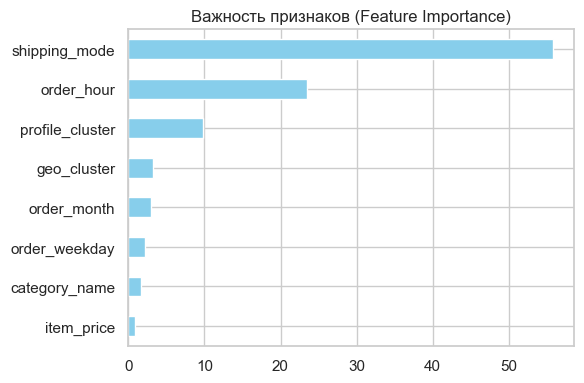

In [59]:
plt.figure(figsize=(6, 4))
importances.plot(kind='barh', color='skyblue')
plt.title('Важность признаков (Feature Importance)')
plt.tight_layout()
plt.show()

отчетливо видно, что созданные кластеры стали ключевыми «подсказчиками» для модели, потеснив категорию товара и день недели.
#### Технический инсайт
В ходе экспериментов было установлено, что оптимальная степень детализации системы достигается при:Geo_K = 8 (логистические макро-зоны).Profile_K = 30 (поведенческие микро-сегменты). Увеличение количества гео-кластеров (например, до 20 ) приводило к снижению качества на валидации. Это связано с тем, что слишком мелкое дробление данных заставляет модель «зазубривать» шум и индивидуальные особенности маленьких групп клиентов, что ведет к переобучению и потере способности обобщать данные на новых заказах.
#### Бизнес-рекомендации
На основе работы модели предлагаются следующие шаги для CargaPronto:
 - Проактивное уведомление: Для заказов с вероятностью задержки > 70% автоматически отправлять клиенту SMS с предупреждением. Это снизит уровень негатива и нагрузку на службу поддержки.
 - Оптимизация логистики в «красных» зонах: Обратить внимание на гео-кластеры с аномально высокой частотой задержек. Возможно, в этих регионах стоит пересмотреть контракты с локальными перевозчиками или увеличить нормативное время доставки (ETA).
 - Работа с профилями: Для сегментов клиентов с высоким риском задержек (например, «возвратники») предлагать дополнительные опции страхования или альтернативные, более надежные способы доставки на этапе оформления заказа.
 - Корректировка порога: Учитывая, что модель сейчас склонна пропускать реальные задержки (False Negatives), рекомендуется снизить порог классификации до 0.4, чтобы охватить больше проблемных случаев, даже ценой небольшого роста ложных тревог.